In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Python executable: c:\Users\pawan\Documents\Projects\bearing_fault_diagnosis\.venv\Scripts\python.exe


In [2]:
from scipy.io import loadmat
from pathlib import Path

# Path to our raw data
data_dir = Path("../data/raw")

# Load one recording
file_path = data_dir / "Normal_0.mat"

data = loadmat(file_path)

print("File loaded successfully!")
print("\nVariables inside the file:")

for key in data.keys():
    print(key)

File loaded successfully!

Variables inside the file:
__header__
__version__
__globals__
X097_DE_time
X097_FE_time
X097RPM


In [3]:
import numpy as np

# Find the Drive End vibration variable
de_keys = [key for key in data.keys() if "DE_time" in key]

print("Drive End variables found:", de_keys)

# Extract the signal

de_key = de_keys[0]
signal = data[de_key].squeeze()

print("\nDrive End variable:", de_key)
print("Number of samples:", len(signal))
print("Data type:", signal.dtype)

print("\nFirst 10 samples:")
print(signal[:10])

Drive End variables found: ['X097_DE_time']

Drive End variable: X097_DE_time
Number of samples: 243938
Data type: float64

First 10 samples:
[ 0.05319692  0.08866154  0.09971815  0.05862092 -0.00458954 -0.056952
 -0.07176369 -0.05862092 -0.04652123 -0.04985908]


In [4]:
rpm_keys = [key for key in data.keys() if "RPM" in key]

print("RPM variables found:", rpm_keys)

if rpm_keys:
    rpm = data[rpm_keys[0]].squeeze()
    print("RPM:", rpm)
else:
    print("No RPM variable found.")

RPM variables found: ['X097RPM']
RPM: 1796


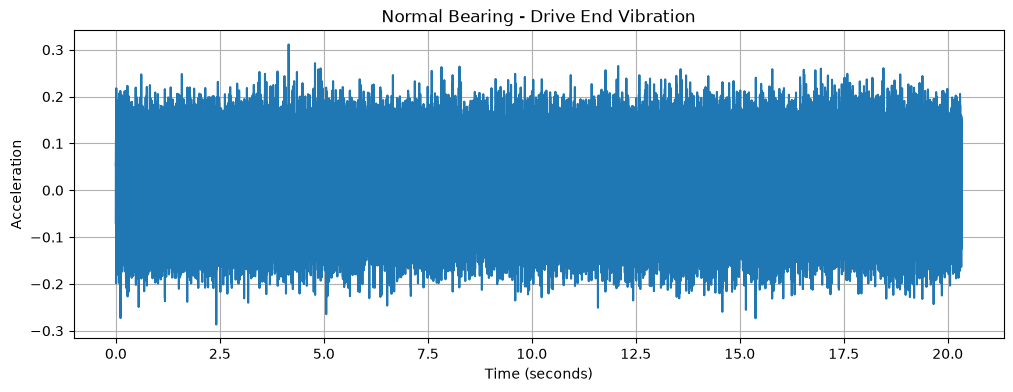

In [5]:
import matplotlib.pyplot as plt

# CWRU 12 kHz data
fs = 12_000  # sampling frequency in Hz

# Create time axis
time = np.arange(len(signal)) / fs

# Plot the entire signal
plt.figure(figsize=(12, 4))

plt.plot(time, signal)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration")
plt.title("Normal Bearing - Drive End Vibration")
plt.grid(True)

plt.show()

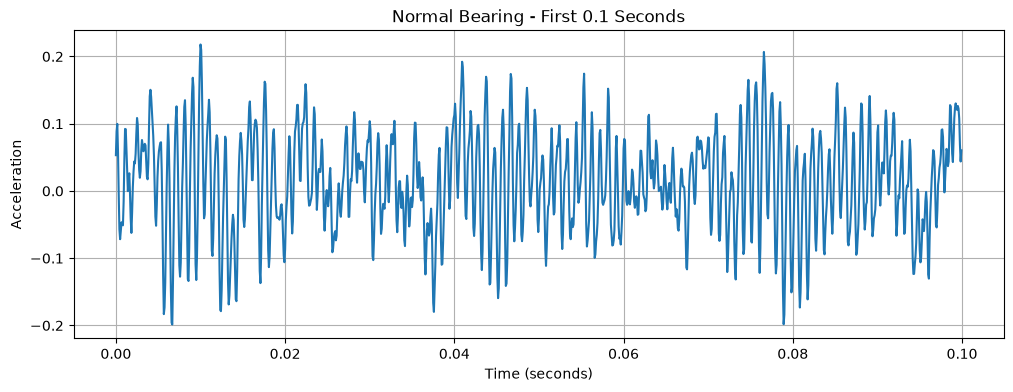

In [6]:
# Look at the first 0.1 seconds
duration = 0.1

num_samples = int(duration * fs)

plt.figure(figsize=(12, 4))

plt.plot(time[:num_samples], signal[:num_samples])

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration")
plt.title("Normal Bearing - First 0.1 Seconds")
plt.grid(True)

plt.show()

In [7]:
fault_data = loadmat(data_dir / "IR021_0.mat")

# Find Drive End signal
fault_de_key = [key for key in fault_data.keys() if "DE_time" in key][0]

# Extract and flatten
fault_signal = fault_data[fault_de_key].squeeze()

print("Fault signal:", fault_de_key)
print("Number of samples:", len(fault_signal))

Fault signal: X209_DE_time
Number of samples: 122136


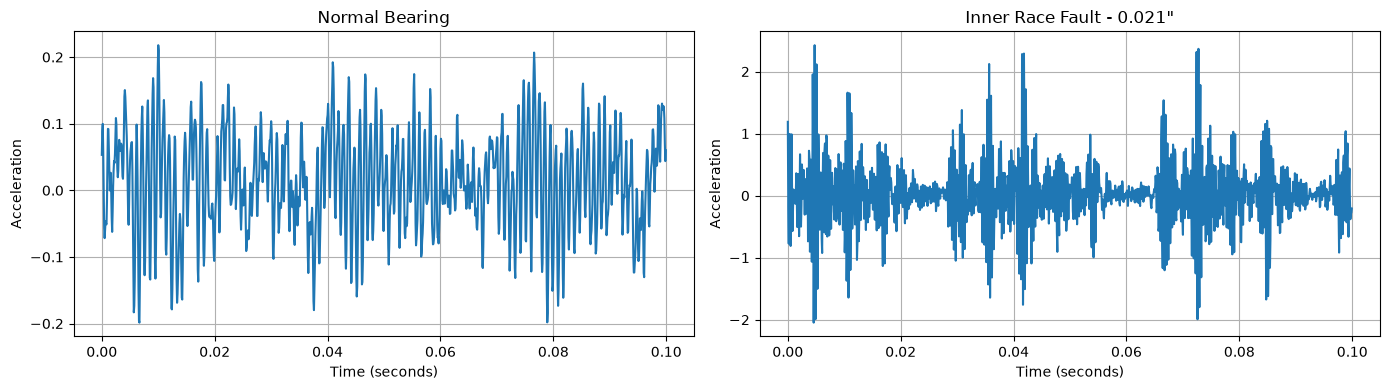

In [8]:
import matplotlib.pyplot as plt

duration = 0.1
num_samples = int(duration * fs)

# Create separate time axes
normal_time = np.arange(num_samples) / fs
fault_time = np.arange(num_samples) / fs

# Create two adjacent plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Normal bearing
axes[0].plot(
    normal_time,
    signal[:num_samples]
)

axes[0].set_title("Normal Bearing")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Acceleration")
axes[0].grid(True)

# Inner race fault
axes[1].plot(
    fault_time,
    fault_signal[:num_samples]
)

axes[1].set_title("Inner Race Fault - 0.021\"")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Acceleration")
axes[1].grid(True)

# Prevent labels/titles from overlapping
plt.tight_layout()

plt.show()

In [9]:
rpm = 1797

# Shaft rotational frequency
fr = rpm / 60

# CWRU Drive End bearing frequency ratios
FTF_ratio = 0.39828
BPFO_ratio = 3.5848
BPFI_ratio = 5.4152
BSF_ratio = 4.7135

# Calculate characteristic frequencies
FTF = FTF_ratio * fr
BPFO = BPFO_ratio * fr
BPFI = BPFI_ratio * fr
BSF = BSF_ratio * fr

print(f"Shaft frequency : {fr:.2f} Hz")
print(f"FTF             : {FTF:.2f} Hz")
print(f"BPFO            : {BPFO:.2f} Hz")
print(f"BPFI            : {BPFI:.2f} Hz")
print(f"BSF             : {BSF:.2f} Hz")

Shaft frequency : 29.95 Hz
FTF             : 11.93 Hz
BPFO            : 107.36 Hz
BPFI            : 162.19 Hz
BSF             : 141.17 Hz


In [10]:
# Take the first 1 second of the inner-race fault

duration = 1.0
N = int(duration * fs)

fault_segment = fault_signal[:N]

print("Number of samples:", len(fault_segment))
print("Duration:", len(fault_segment) / fs, "seconds")

Number of samples: 12000
Duration: 1.0 seconds


In [11]:
# Calculate the FFT

fft_values = np.fft.rfft(fault_segment)

# Corresponding frequency values
frequencies = np.fft.rfftfreq(N, d=1/fs)

# Magnitude of the FFT
magnitude = np.abs(fft_values) / N

print("Number of frequency bins:", len(frequencies))
print("Maximum frequency:", frequencies[-1], "Hz")

Number of frequency bins: 6001
Maximum frequency: 6000.0 Hz


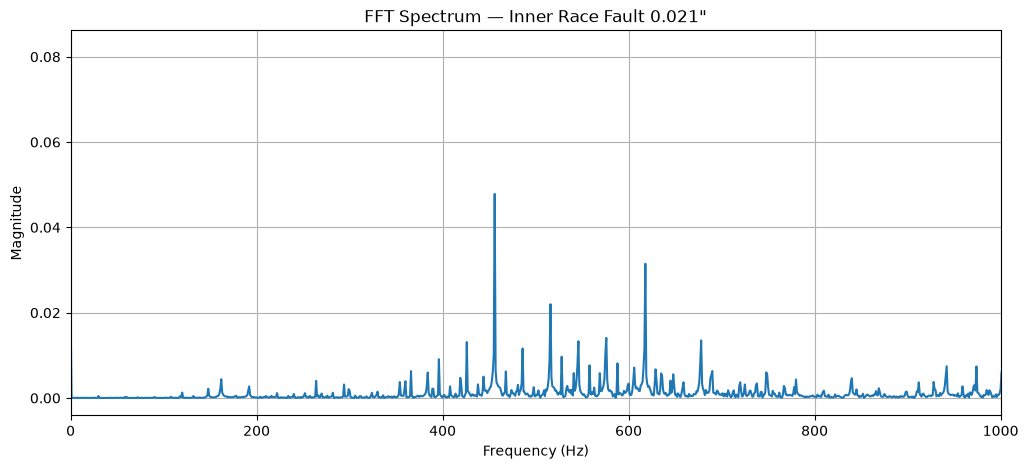

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(frequencies, magnitude)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FFT Spectrum — Inner Race Fault 0.021\"")
plt.xlim(0, 1000)

plt.grid(True)
plt.show()

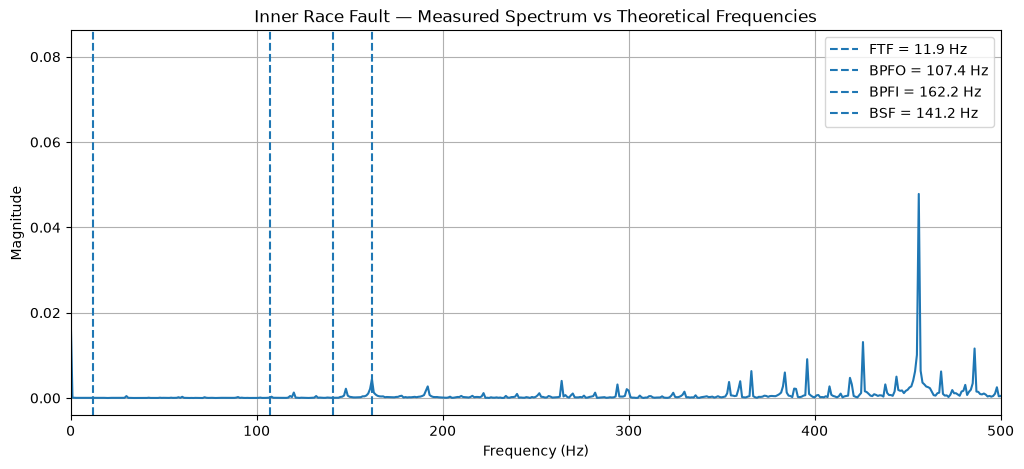

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(frequencies, magnitude)

# Theoretical bearing frequencies
plt.axvline(FTF, linestyle="--", label=f"FTF = {FTF:.1f} Hz")
plt.axvline(BPFO, linestyle="--", label=f"BPFO = {BPFO:.1f} Hz")
plt.axvline(BPFI, linestyle="--", label=f"BPFI = {BPFI:.1f} Hz")
plt.axvline(BSF, linestyle="--", label=f"BSF = {BSF:.1f} Hz")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Inner Race Fault — Measured Spectrum vs Theoretical Frequencies")

plt.xlim(0, 500)

plt.legend()
plt.grid(True)

plt.show()

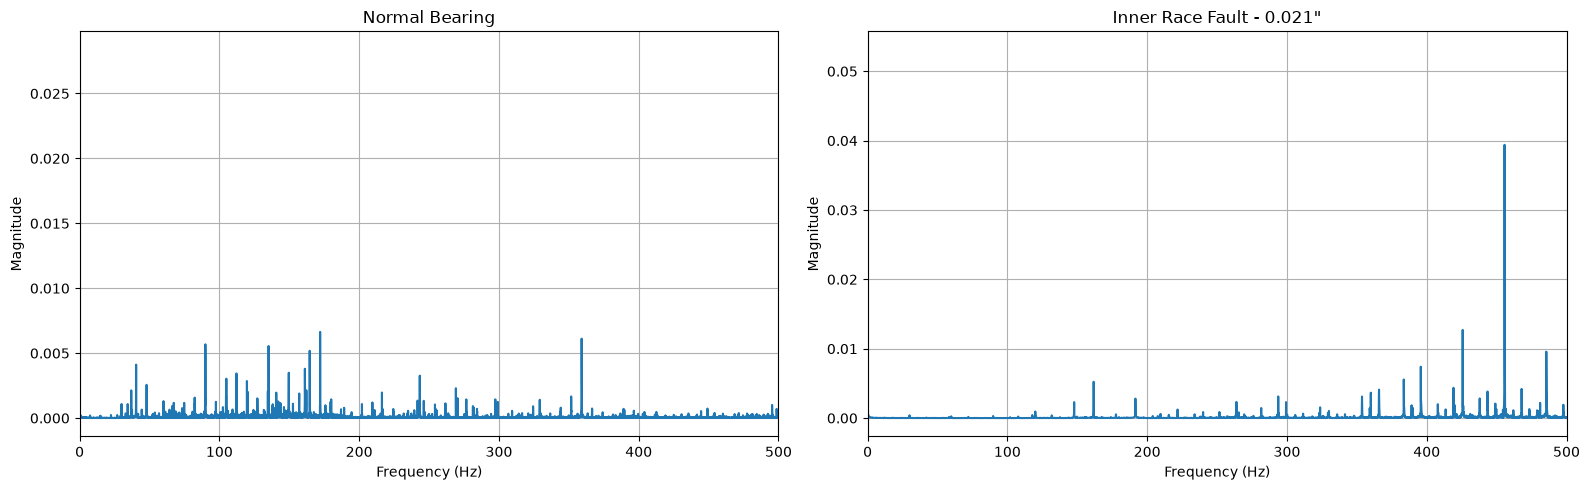

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Function to calculate a single-sided FFT
# --------------------------------------------------

def calculate_fft(signal, fs):
    """
    Calculate the single-sided FFT magnitude spectrum.

    Parameters
    ----------
    signal : array
        Time-domain vibration signal
    fs : int
        Sampling frequency in Hz

    Returns
    -------
    frequencies : array
        Frequency values in Hz
    magnitude : array
        FFT magnitude
    """

    N = len(signal)

    # FFT
    fft_values = np.fft.fft(signal)

    # Frequency axis
    frequencies = np.fft.fftfreq(N, 1 / fs)

    # Keep only positive frequencies
    positive = frequencies >= 0

    frequencies = frequencies[positive]
    magnitude = np.abs(fft_values[positive]) / N

    return frequencies, magnitude


# --------------------------------------------------
# Calculate FFTs
# --------------------------------------------------

fs = 12000  # CWRU sampling frequency

freq_normal, fft_normal = calculate_fft(signal, fs)
freq_fault, fft_fault = calculate_fft(fault_signal, fs)


# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Normal
axes[0].plot(freq_normal, fft_normal)

axes[0].set_title("Normal Bearing")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude")
axes[0].set_xlim(0, 500)
axes[0].grid(True)


# Inner-race fault
axes[1].plot(freq_fault, fft_fault)

axes[1].set_title('Inner Race Fault - 0.021"')
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude")
axes[1].set_xlim(0, 500)
axes[1].grid(True)


plt.tight_layout()
plt.show()

In [ ]:
# Theoretical bearing frequencies
FTF = 11.9
BPFO = 107.4
BSF = 141.2
BPFI = 162.2

fault_frequencies = {
    "FTF": FTF,
    "BPFO": BPFO,
    "BSF": BSF,
    "BPFI": BPFI
}


fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --------------------------------------------------
# Normal bearing
# --------------------------------------------------

axes[0].plot(freq_normal, fft_normal)

for name, freq in fault_frequencies.items():
    axes[0].axvline(
        freq,
        linestyle="--",
        alpha=0.7,
        label=f"{name} = {freq:.1f} Hz"
    )

axes[0].set_title("Normal Bearing — 0 to 250 Hz")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude")
axes[0].set_xlim(0, 250)
axes[0].grid(True)
axes[0].legend()


# --------------------------------------------------
# Inner-race fault
# --------------------------------------------------

axes[1].plot(freq_fault, fft_fault)

for name, freq in fault_frequencies.items():
    axes[1].axvline(
        freq,
        linestyle="--",
        alpha=0.7,
        label=f"{name} = {freq:.1f} Hz"
    )

axes[1].set_title('Inner Race Fault — 0 to 250 Hz')
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude")
axes[1].set_xlim(0, 250)
axes[1].grid(True)
axes[1].legend()


plt.tight_layout()
plt.show()